In [7]:
pip install geopandas matplotlib cartopy rasterio earthpy

  Using cached attrs-26.1.0-py3-none-any.whl.metadata (8.8 kB)
   ---------------------------------------- 0.0/9.0 MB ? eta -:--:--
   ------- -------------------------------- 1.6/9.0 MB 9.3 MB/s eta 0:00:01
   ---------------- ----------------------- 3.7/9.0 MB 9.6 MB/s eta 0:00:01
   ------------------------- -------------- 5.8/9.0 MB 9.4 MB/s eta 0:00:01
   --------------------------------- ------ 7.6/9.0 MB 9.2 MB/s eta 0:00:01
   ---------------------------------------- 9.0/9.0 MB 8.7 MB/s eta 0:00:00
   ---------------------------------------- 0.0/30.7 MB ? eta -:--:--
   -- ------------------------------------- 1.6/30.7 MB 8.2 MB/s eta 0:00:04
   ---- ----------------------------------- 3.1/30.7 MB 7.6 MB/s eta 0:00:04
   ------ --------------------------------- 5.0/30.7 MB 7.6 MB/s eta 0:00:04
   -------- ------------------------------- 6.3/30.7 MB 7.4 MB/s eta 0:00:04
   ---------- ----------------------------- 8.1/30.7 MB 7.7 MB/s eta 0:00:03
   ----------- ------------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


=== [RECIPE CHECK] INSPEKSI DATA VECTOR (GeoJSON USGS) ===


c:\Users\LENOVO\.conda\envs\pengprog\Lib\site-packages\pyogrio\core.py:35: RuntimeWarning: Could not detect GDAL data files.  Set GDAL_DATA environment variable to the correct path.
  _init_gdal_data()


Geometry Type : ['Point']
CRS Vector    : EPSG:4979
Bounds Vector : [-179.9919  -63.5619  179.9814   82.5871]

=== [RECIPE CHECK] INSPEKSI DATA RASTER (DEM GEBCO) ===
CRS Raster    : EPSG:4326
Bounds Raster : BoundingBox(left=123.99999999999997, bottom=-2.0000000000000036, right=128.99999999999997, top=3.000000000000001)

[RESULT SUCCESS] Map berhasil diexport ke Artifact Path: artifacts/recipes/visualization\r-geo-001_maluku.png


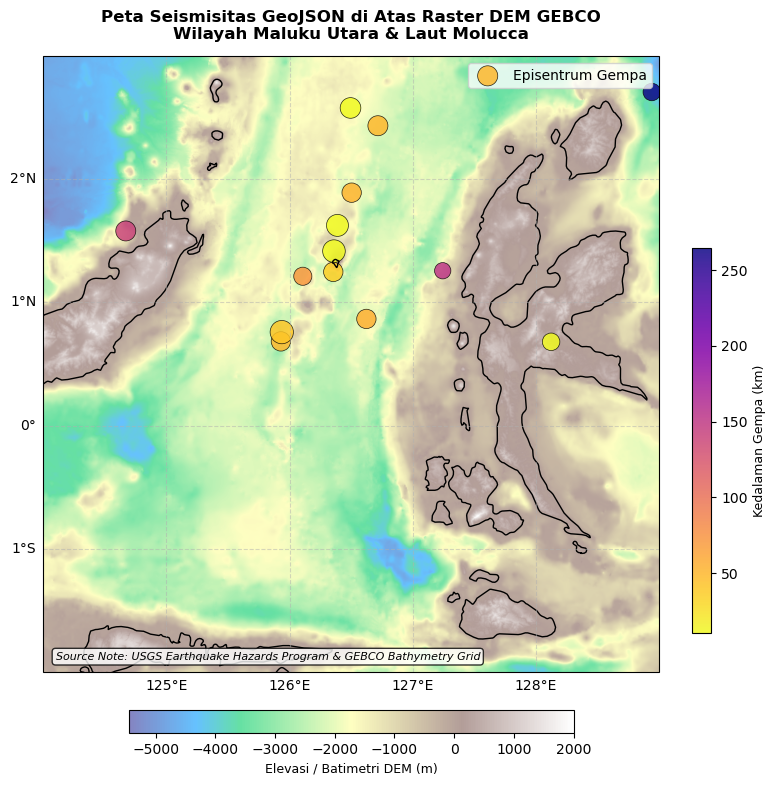

In [1]:
import os
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import geopandas as gpd
import matplotlib.pyplot as plt
import rasterio

# ==============================================================================
# 1. AI ROLE CHECK: INSPEKSI GEOMETRY TYPE, CRS, & EXTENT
# ==============================================================================
print("=== [RECIPE CHECK] INSPEKSI DATA VECTOR (GeoJSON USGS) ===")
geojson_url = (
    "https://earthquake.usgs.gov/earthquakes/feed/v1.0/summary/all_month.geojson"
)
gdf_gempa = gpd.read_file(geojson_url)

print("Geometry Type :", gdf_gempa.geometry.type.unique())
print("CRS Vector    :", gdf_gempa.crs)
print("Bounds Vector :", gdf_gempa.total_bounds)

print("\n=== [RECIPE CHECK] INSPEKSI DATA RASTER (DEM GEBCO) ===")
raster_path = "dem_maluku.tif"

with rasterio.open(raster_path) as src:
    dem_data = src.read(1)
    raster_crs = src.crs
    raster_bounds = src.bounds

print("CRS Raster    :", raster_crs)
print("Bounds Raster :", raster_bounds)

# ==============================================================================
# 2. REPROJECT & SPATIAL FILTERING + EKSTRAK KEDALAMAN (Z)
# ==============================================================================
if gdf_gempa.crs != "EPSG:4326":
    gdf_gempa = gdf_gempa.to_crs("EPSG:4326")

# Bounding Box Maluku Utara / Laut Molucca
minx, miny, maxx, maxy = (124.0, -2.0, 129.0, 3.0)
gdf_gempa_target = gdf_gempa.cx[minx:maxx, miny:maxy].copy()

# Ekstrak nilai z (depth) dari geometri Point 3D GeoJSON USGS
if not gdf_gempa_target.empty:
    gdf_gempa_target["depth"] = gdf_gempa_target.geometry.z

# ==============================================================================
# 3. PLOTTING SIKLUS LAYER ORDER
# ==============================================================================
fig, ax = plt.subplots(
    figsize=(10, 10), subplot_kw={"projection": ccrs.PlateCarree()}
)

# LAYER 1: Garis Pantai
ax.add_feature(cfeature.COASTLINE, linewidth=1.0, edgecolor="black")
ax.add_feature(
    cfeature.BORDERS, linestyle=":", linewidth=0.8, edgecolor="gray"
)

# LAYER 2: Raster DEM GEBCO
extent_raster = [
    raster_bounds.left,
    raster_bounds.right,
    raster_bounds.bottom,
    raster_bounds.top,
]
dem_img = ax.imshow(
    dem_data,
    extent=extent_raster,
    cmap="terrain",
    origin="upper",
    alpha=0.6,
    transform=ccrs.PlateCarree(),
)

# LAYER 3: Feature GeoJSON Vector (Episentrum Gempa)
if not gdf_gempa_target.empty:
    scatter = ax.scatter(
        gdf_gempa_target.geometry.x,
        gdf_gempa_target.geometry.y,
        s=(gdf_gempa_target["mag"] ** 3) * 2,  # Ukuran proporsional Magnitudo
        c=gdf_gempa_target["depth"],  # Warna proporsional Kedalaman (km)
        cmap="plasma_r",
        edgecolors="black",
        linewidth=0.5,
        alpha=0.85,
        transform=ccrs.PlateCarree(),
        label="Episentrum Gempa",
    )

    # LEGEND 1: Colorbar Kedalaman Gempa
    cbar_gempa = plt.colorbar(
        scatter, ax=ax, orientation="vertical", pad=0.03, shrink=0.5
    )
    cbar_gempa.set_label("Kedalaman Gempa (km)", fontsize=9)

# LEGEND 2: Colorbar Elevasi DEM
cbar_dem = plt.colorbar(
    dem_img, ax=ax, orientation="horizontal", pad=0.05, shrink=0.7
)
cbar_dem.set_label("Elevasi / Batimetri DEM (m)", fontsize=9)

# ==============================================================================
# 4. MAP ELEMENTS
# ==============================================================================
ax.set_extent([minx, maxx, miny, maxy], crs=ccrs.PlateCarree())

gl = ax.gridlines(
    draw_labels=True, crs=ccrs.PlateCarree(), linestyle="--", alpha=0.5
)
gl.top_labels = False
gl.right_labels = False

plt.title(
    "Peta Seismisitas GeoJSON di Atas Raster DEM GEBCO\nWilayah Maluku Utara & Laut Molucca",
    fontsize=12,
    fontweight="bold",
    pad=12,
)

plt.text(
    0.02,
    0.02,
    "Source Note: USGS Earthquake Hazards Program & GEBCO Bathymetry Grid",
    transform=ax.transAxes,
    fontsize=8,
    style="italic",
    bbox=dict(boxstyle="round", facecolor="white", alpha=0.8),
)

if not gdf_gempa_target.empty:
    ax.legend(loc="upper right")

# ==============================================================================
# 5. EXPORT RESULT & ARTIFACT PATH
# ==============================================================================
output_dir = "artifacts/recipes/visualization"
os.makedirs(output_dir, exist_ok=True)
export_path = os.path.join(output_dir, "r-geo-001_maluku.png")

plt.savefig(export_path, dpi=300, bbox_inches="tight")
print(
    f"\n[RESULT SUCCESS] Map berhasil diexport ke Artifact Path: {export_path}"
)
plt.show()